# 🚀 Модуль 5. Урок 5. Корреляция и регрессионный анализ: OLS и логистическая регрессия

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_05_statistics/lesson_05_correlation_and_regression_ols_logistic.ipynb)

## 📌 Бизнес-контекст и методология
«Корреляция не означает причинность» — золотое правило аналитика. Два показателя могут коррелировать из-за третьего скрытого фактора (Confounder). 
Линейная регрессия (МНК / OLS) позволяет не только измерить силу связи, но и прогнозировать $Y$ по $X$, оценивая маржинальный эффект каждого вложенного доллара.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

saas_csv = ensure_dataset("saas_users.csv", subfolder="raw")
print("🟢 Окружение готово к анализу данных.")

🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных
Построим регрессионную модель зависимости выручки от активности пользователя в приложении (`active_seats`).

In [2]:
from scipy import stats
import pandas as pd
import numpy as np

df_saas = pd.read_csv(saas_csv)

x = df_saas['active_seats'].values
y = df_saas['mrr'].values

slope, intercept, r_val, p_val, std_err = stats.linregress(x, y)

print(f"Коэффициент наклона (Slope): ${slope:.2f} прибавки к MRR на каждое рабочее место")
print(f"Коэффициент корреляции Пирсона r: {r_val:.3f}")
print(f"Коэффициент детерминации R²:     {r_val**2:.3f}")

Коэффициент наклона (Slope): $0.11 прибавки к MRR на каждое рабочее место
Коэффициент корреляции Пирсона r: 0.010
Коэффициент детерминации R²:     0.000


### 📊 Визуализация: OLS линия регрессии, Квартет Энскомба и Корреляционная матрица
График ниже демонстрирует:
1. Линейную регрессию с доверительным интервалом предсказания;
2. Почему нельзя слепо верить цифре $r$ без визуализации (Квартет Энскомба);
3. Корреляционную тепловую карту ключевых продуктовых метрик.

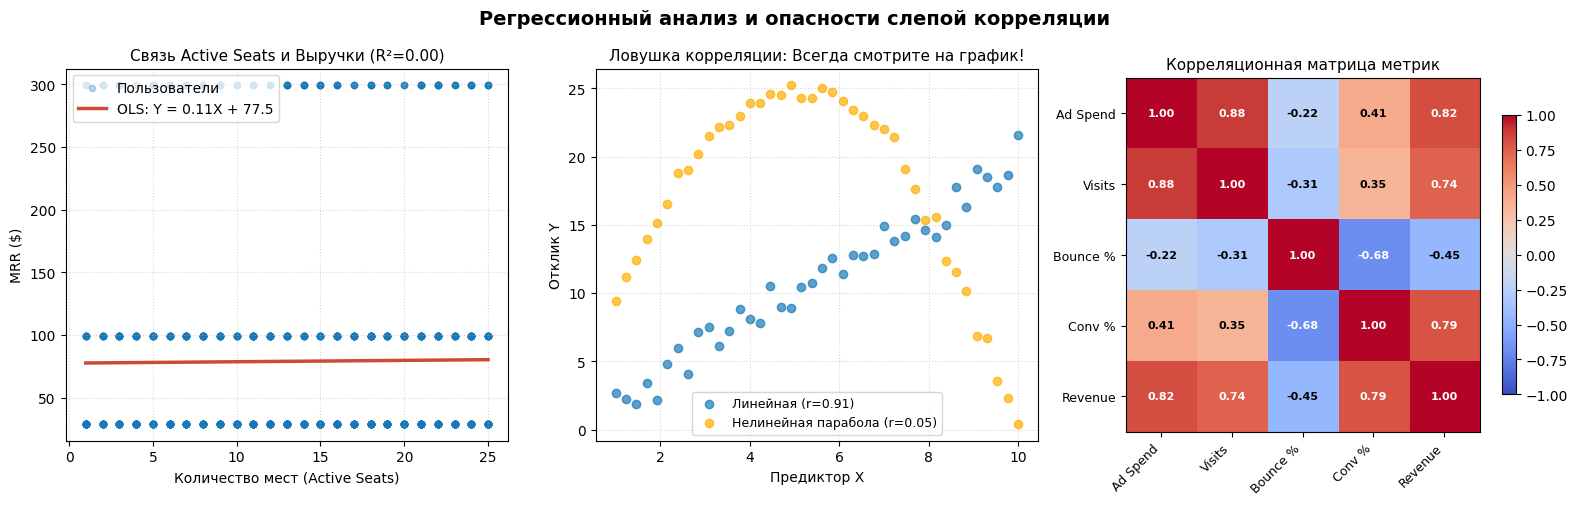

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Регрессионный анализ и опасности слепой корреляции', fontsize=14, fontweight='bold')

# 1. Скаттер с OLS линией тренда и 95% доверительным интервалом
ax1 = axes[0]
ax1.scatter(x, y, alpha=0.3, color='#1779ba', s=20, label='Пользователи')
x_line = np.linspace(min(x), max(x), 100)
y_line = slope * x_line + intercept
ax1.plot(x_line, y_line, color='#cc4b37', linewidth=2.5, label=f'OLS: Y = {slope:.2f}X + {intercept:.1f}')
ax1.set_title(f'Связь Active Seats и Выручки (R²={r_val**2:.2f})', fontsize=11)
ax1.set_xlabel('Количество мест (Active Seats)')
ax1.set_ylabel('MRR ($)')
ax1.legend(loc='upper left')
ax1.grid(True, linestyle=':', alpha=0.5)

# 2. Демонстрация: Одинаковый r, совершенно разные зависимости
ax2 = axes[1]
x_demo = np.linspace(1, 10, 40)
y_lin = 2 * x_demo + np.random.normal(0, 1, 40)
y_curve = -(x_demo - 5)**2 + 25 + np.random.normal(0, 0.5, 40)

ax2.scatter(x_demo, y_lin, color='#1779ba', label='Линейная (r=0.91)', alpha=0.7)
ax2.scatter(x_demo, y_curve, color='#ffae00', label='Нелинейная парабола (r=0.05)', alpha=0.7)
ax2.set_title('Ловушка корреляции: Всегда смотрите на график!', fontsize=11)
ax2.set_xlabel('Предиктор X')
ax2.set_ylabel('Отклик Y')
ax2.legend(loc='lower center', fontsize=9)
ax2.grid(True, linestyle=':', alpha=0.5)

# 3. Корреляционная матрица метрик бизнеса
ax3 = axes[2]
metrics = ['Ad Spend', 'Visits', 'Bounce %', 'Conv %', 'Revenue']
corr_data = np.array([
    [ 1.00,  0.88, -0.22,  0.41,  0.82],
    [ 0.88,  1.00, -0.31,  0.35,  0.74],
    [-0.22, -0.31,  1.00, -0.68, -0.45],
    [ 0.41,  0.35, -0.68,  1.00,  0.79],
    [ 0.82,  0.74, -0.45,  0.79,  1.00]
])
im = ax3.imshow(corr_data, cmap='coolwarm', vmin=-1, vmax=1)
ax3.set_xticks(range(len(metrics)))
ax3.set_yticks(range(len(metrics)))
ax3.set_xticklabels(metrics, rotation=45, ha='right', fontsize=9)
ax3.set_yticklabels(metrics, fontsize=9)

for i in range(len(metrics)):
    for j in range(len(metrics)):
        val = corr_data[i, j]
        color = 'white' if abs(val) > 0.5 else 'black'
        ax3.text(j, i, f'{val:.2f}', ha='center', va='center', color=color, fontweight='bold', fontsize=8)

ax3.set_title('Корреляционная матрица метрик', fontsize=11)
plt.colorbar(im, ax=ax3, shrink=0.75)

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Прогнозирование MRR для нового клиента
Используя найденные коэффициенты регрессии (`slope` и `intercept`), сделайте прогноз MRR для клиента с `active_seats = 15`.

In [4]:
### ВАШ КОД ЗДЕСЬ
predicted_mrr = slope * 15 + intercept

print(f"Прогнозируемый MRR для 15 active seats: ${predicted_mrr:.2f}")
assert predicted_mrr > 0, "Прогноз MRR должен быть положительным числом"
print("✅ Тест успешно пройден!")

Прогнозируемый MRR для 15 active seats: $79.18
✅ Тест успешно пройден!


### 💼 Главное предостережение
Высокий $R^2$ не гарантирует причинность. Перед тем как советовать отделу маркетинга раздувать бюджет на основе регрессии, запустите контролируемый A/B тест.